In [22]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [23]:
df=pd.read_excel("data/default_cred_clients.xls",header=1)
df.head

<bound method NDFrame.head of           ID  LIMIT_BAL  SEX  EDUCATION  MARRIAGE  AGE  PAY_0  PAY_2  PAY_3  \
0          1      20000    2          2         1   24      2      2     -1   
1          2     120000    2          2         2   26     -1      2      0   
2          3      90000    2          2         2   34      0      0      0   
3          4      50000    2          2         1   37      0      0      0   
4          5      50000    1          2         1   57     -1      0     -1   
...      ...        ...  ...        ...       ...  ...    ...    ...    ...   
29995  29996     220000    1          3         1   39      0      0      0   
29996  29997     150000    1          3         2   43     -1     -1     -1   
29997  29998      30000    1          2         2   37      4      3      2   
29998  29999      80000    1          3         1   41      1     -1      0   
29999  30000      50000    1          2         1   46      0      0      0   

       PAY_4  ...  BI

In [24]:
print(df.head())
print("Shape:", df.shape)
print(df.info())


   ID  LIMIT_BAL  SEX  EDUCATION  MARRIAGE  AGE  PAY_0  PAY_2  PAY_3  PAY_4  \
0   1      20000    2          2         1   24      2      2     -1     -1   
1   2     120000    2          2         2   26     -1      2      0      0   
2   3      90000    2          2         2   34      0      0      0      0   
3   4      50000    2          2         1   37      0      0      0      0   
4   5      50000    1          2         1   57     -1      0     -1      0   

   ...  BILL_AMT4  BILL_AMT5  BILL_AMT6  PAY_AMT1  PAY_AMT2  PAY_AMT3  \
0  ...          0          0          0         0       689         0   
1  ...       3272       3455       3261         0      1000      1000   
2  ...      14331      14948      15549      1518      1500      1000   
3  ...      28314      28959      29547      2000      2019      1200   
4  ...      20940      19146      19131      2000     36681     10000   

   PAY_AMT4  PAY_AMT5  PAY_AMT6  default payment next month  
0         0         0   

In [25]:
df["default payment next month"].value_counts()

default payment next month
0    23364
1     6636
Name: count, dtype: int64

In [26]:
missing_values = df.isnull().sum()

print(missing_values[missing_values > 0])

Series([], dtype: int64)


In [27]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [28]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
ID,30000.0,15000.500000,8660.398374,1.0,7500.75,15000.5,22500.25,30000.0
LIMIT_BAL,30000.0,167484.322667,129747.661567,10000.0,50000.00,140000.0,240000.00,1000000.0
SEX,30000.0,1.603733,0.489129,1.0,1.00,2.0,2.00,2.0
EDUCATION,30000.0,1.853133,0.790349,0.0,1.00,2.0,2.00,6.0
MARRIAGE,30000.0,1.551867,0.521970,0.0,1.00,2.0,2.00,3.0
AGE,30000.0,35.485500,9.217904,21.0,28.00,34.0,41.00,79.0
PAY_0,30000.0,-0.016700,1.123802,-2.0,-1.00,0.0,0.00,8.0
PAY_2,30000.0,-0.133767,1.197186,-2.0,-1.00,0.0,0.00,8.0
PAY_3,30000.0,-0.166200,1.196868,-2.0,-1.00,0.0,0.00,8.0
PAY_4,30000.0,-0.220667,1.169139,-2.0,-1.00,0.0,0.00,8.0


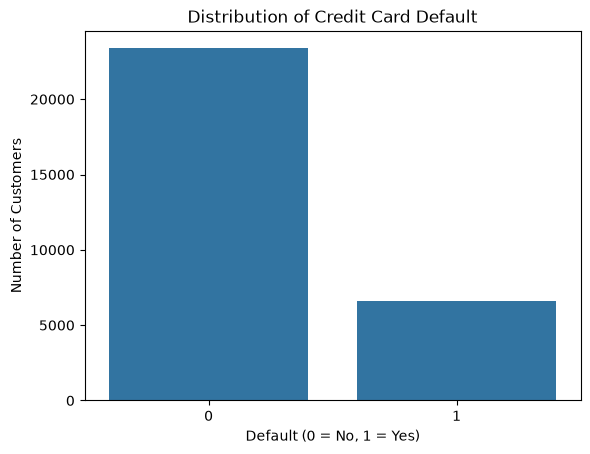

In [29]:


sns.countplot(data=df, x="default payment next month")
plt.title("Distribution of Credit Card Default")
plt.xlabel("Default (0 = No, 1 = Yes)")
plt.ylabel("Number of Customers")
plt.show()

In [30]:
default_rate = df["default payment next month"].mean() * 100

print(f"Default rate: {default_rate:.2f}%")
print(f"Non-default rate: {100 - default_rate:.2f}%")

Default rate: 22.12%
Non-default rate: 77.88%


In [31]:
default_rate = df["default payment next month"].mean() * 100

print(f"Default rate: {default_rate:.2f}%")
print(f"Non-default rate: {100 - default_rate:.2f}%")

Default rate: 22.12%
Non-default rate: 77.88%


In [32]:
# Average values grouped by default status
df.groupby("default payment next month")[
    ["LIMIT_BAL", "AGE"]
].mean()

,LIMIT_BAL,AGE
default payment next month,,
0,178099.726074,35.417266
1,130109.656420,35.725738


In [33]:
# Separate input features and target
X = df.drop(
    columns=["default payment next month", "ID"]
)

y = df["default payment next month"]

print("Features:", X.shape)
print("Target:", y.shape)

Features: (30000, 23)
Target: (30000,)


In [34]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True))

Training features: (24000, 23)
Testing features: (6000, 23)

Training target distribution:
default payment next month
0    0.778792
1    0.221208
Name: proportion, dtype: float64

Testing target distribution:
default payment next month
0    0.778833
1    0.221167
Name: proportion, dtype: float64


In [35]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

logistic_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=1000))
])

logistic_model.fit(X_train, y_train)

print("Logistic Regression training completed!")

Logistic Regression training completed!


In [36]:
y_pred = logistic_model.predict(X_test)

print(y_pred[:20])

[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]


In [37]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

y_prob = logistic_model.predict_proba(X_test)[:, 1]

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, y_pred, zero_division=0), 4))
print("F1-score:", round(f1_score(y_test, y_pred, zero_division=0), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

Accuracy: 0.8077
Precision: 0.6868
Recall: 0.2396
F1-score: 0.3553
ROC-AUC: 0.7076

Classification Report:
              precision    recall  f1-score   support

           0       0.82      0.97      0.89      4673
           1       0.69      0.24      0.36      1327

    accuracy                           0.81      6000
   macro avg       0.75      0.60      0.62      6000
weighted avg       0.79      0.81      0.77      6000



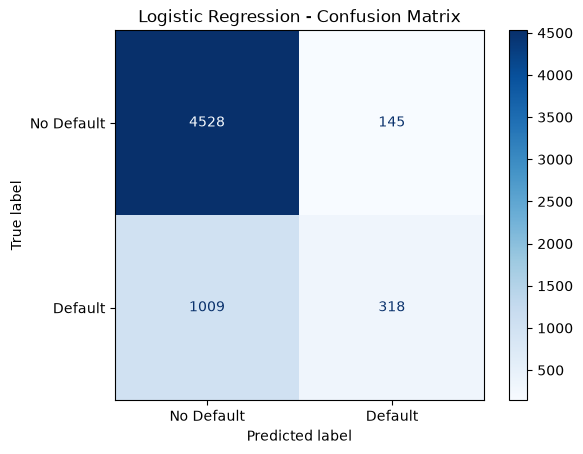

In [38]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["No Default", "Default"],
    cmap="Blues"
)

plt.title("Logistic Regression - Confusion Matrix")
plt.show()

In [39]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=12,
    min_samples_leaf=5,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)
rf_prob = rf_model.predict_proba(X_test)[:, 1]

print("Random Forest Results")
print("---------------------")
print("Accuracy:", round(accuracy_score(y_test, rf_pred), 4))
print("Precision:", round(precision_score(y_test, rf_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, rf_pred, zero_division=0), 4))
print("F1-score:", round(f1_score(y_test, rf_pred, zero_division=0), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, rf_prob), 4))

Random Forest Results
---------------------
Accuracy: 0.7782
Precision: 0.4987
Recall: 0.5931
F1-score: 0.5418
ROC-AUC: 0.7747


In [40]:
import pandas as pd

comparison = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"],
    "Logistic Regression": [
        accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred, zero_division=0),
        recall_score(y_test, y_pred, zero_division=0),
        f1_score(y_test, y_pred, zero_division=0),
        roc_auc_score(y_test, y_prob)
    ],
    "Random Forest": [
        accuracy_score(y_test, rf_pred),
        precision_score(y_test, rf_pred, zero_division=0),
        recall_score(y_test, rf_pred, zero_division=0),
        f1_score(y_test, rf_pred, zero_division=0),
        roc_auc_score(y_test, rf_prob)
    ]
})

comparison.round(4)

,Metric,Logistic Regression,Random Forest
0,Accuracy,0.8077,0.7782
1,Precision,0.6868,0.4987
2,Recall,0.2396,0.5931
3,F1-score,0.3553,0.5418
4,ROC-AUC,0.7076,0.7747


      Feature  Importance
5       PAY_0    0.224074
6       PAY_2    0.087745
7       PAY_3    0.053312
0   LIMIT_BAL    0.051793
8       PAY_4    0.051705
18   PAY_AMT2    0.044013
11  BILL_AMT1    0.043767
17   PAY_AMT1    0.043064
19   PAY_AMT3    0.037637
10      PAY_6    0.037354
12  BILL_AMT2    0.035661
20   PAY_AMT4    0.032445
13  BILL_AMT3    0.031123
9       PAY_5    0.031024
14  BILL_AMT4    0.030997


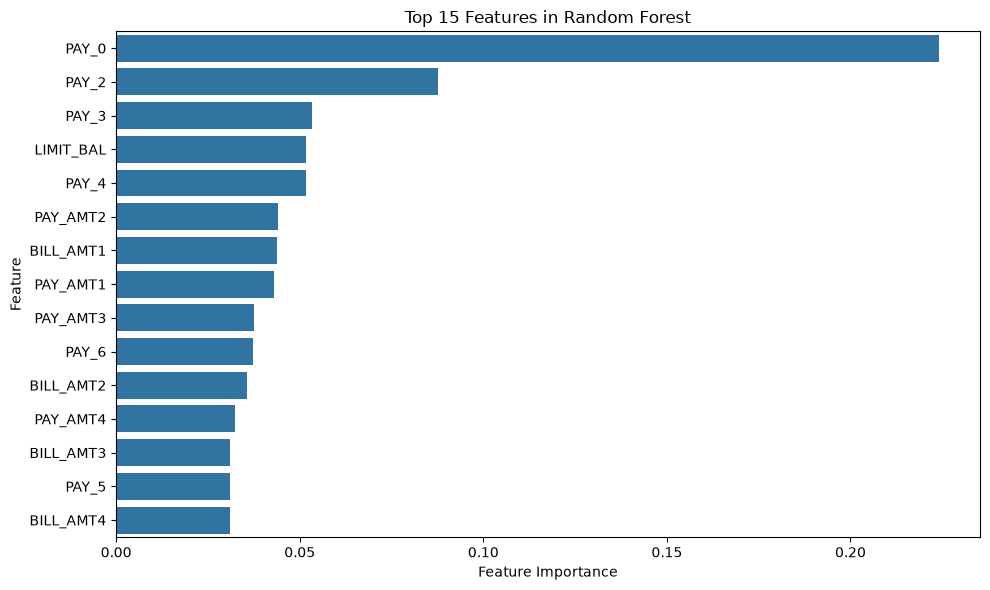

In [41]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_model.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

print(importance.head(15))

plt.figure(figsize=(10, 6))
sns.barplot(
    data=importance.head(15),
    x="Importance",
    y="Feature"
)

plt.title("Top 15 Features in Random Forest")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

In [42]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier

# Split the existing training data
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

# Train Random Forest on the smaller training portion
threshold_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=12,
    min_samples_leaf=5,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

threshold_model.fit(X_fit, y_fit)

# Get probabilities for the validation set
val_prob = threshold_model.predict_proba(X_val)[:, 1]

print("Training and validation completed!")
print("Validation records:", len(y_val))

Training and validation completed!
Validation records: 4800


In [43]:
import pandas as pd
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)

results = []

for threshold in [0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60]:
    val_pred = (val_prob >= threshold).astype(int)

    results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_val, val_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_val, val_pred, zero_division=0
        ),
        "F1-score": f1_score(
            y_val, val_pred, zero_division=0
        )
    })

threshold_results = pd.DataFrame(results)

print(threshold_results.round(4).to_string(index=False))

 Threshold  Precision  Recall  F1-score
      0.30     0.3076  0.8823    0.4562
      0.35     0.3579  0.8136    0.4971
      0.40     0.4132  0.6968    0.5188
      0.45     0.4539  0.6299    0.5276
      0.50     0.4988  0.5838    0.5380
      0.55     0.5303  0.5443    0.5372
      0.60     0.5692  0.5075    0.5366


In [44]:
import pandas as pd
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)

results = []

for threshold in [0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60]:
    val_pred = (val_prob >= threshold).astype(int)

    results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_val, val_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_val, val_pred, zero_division=0
        ),
        "F1-score": f1_score(
            y_val, val_pred, zero_division=0
        )
    })

threshold_results = pd.DataFrame(results)

print(threshold_results.round(4).to_string(index=False))

 Threshold  Precision  Recall  F1-score
      0.30     0.3076  0.8823    0.4562
      0.35     0.3579  0.8136    0.4971
      0.40     0.4132  0.6968    0.5188
      0.45     0.4539  0.6299    0.5276
      0.50     0.4988  0.5838    0.5380
      0.55     0.5303  0.5443    0.5372
      0.60     0.5692  0.5075    0.5366


In [45]:
from sklearn.ensemble import RandomForestClassifier

# Train on the complete training set
final_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=12,
    min_samples_leaf=5,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

final_model.fit(X_train, y_train)

print("Final model trained successfully!")

Final model trained successfully!


Final Random Forest Results
----------------------------
Threshold: 0.5
Accuracy: 0.7782
Precision: 0.4987
Recall: 0.5931
F1-score: 0.5418
ROC-AUC: 0.7747

Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.83      0.85      4673
           1       0.50      0.59      0.54      1327

    accuracy                           0.78      6000
   macro avg       0.69      0.71      0.70      6000
weighted avg       0.79      0.78      0.78      6000



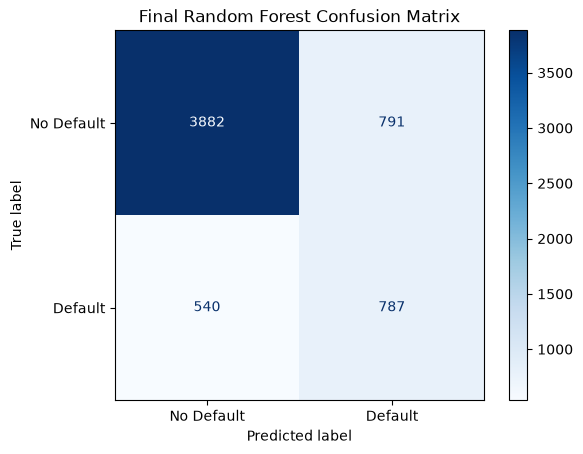

In [46]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Predict probabilities on the untouched test set
test_prob = final_model.predict_proba(X_test)[:, 1]

# Apply the selected threshold
selected_threshold = 0.50
test_pred = (test_prob >= selected_threshold).astype(int)

print("Final Random Forest Results")
print("----------------------------")
print("Threshold:", selected_threshold)
print("Accuracy:", round(accuracy_score(y_test, test_pred), 4))
print("Precision:", round(precision_score(y_test, test_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, test_pred, zero_division=0), 4))
print("F1-score:", round(f1_score(y_test, test_pred, zero_division=0), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, test_prob), 4))

print("\nClassification Report:")
print(classification_report(y_test, test_pred, zero_division=0))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_pred,
    display_labels=["No Default", "Default"],
    cmap="Blues"
)

plt.title("Final Random Forest Confusion Matrix")
plt.show()

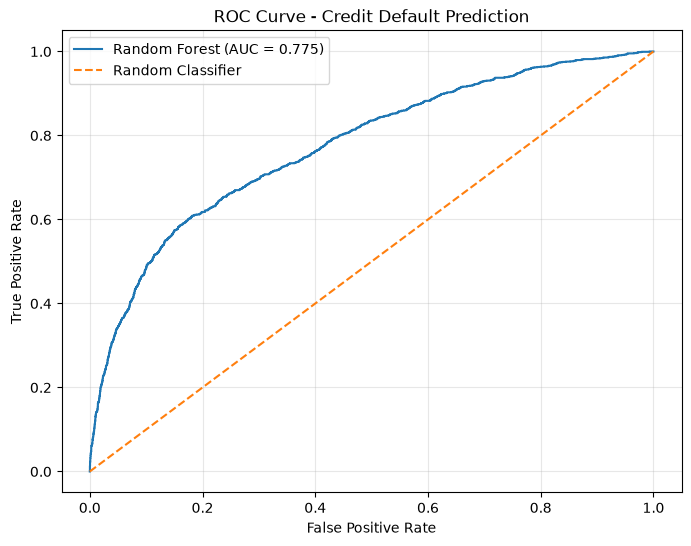

In [47]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

# Calculate ROC curve values
fpr, tpr, thresholds = roc_curve(y_test, test_prob)

# Calculate ROC-AUC score
roc_auc = roc_auc_score(y_test, test_prob)

# Plot ROC curve
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f"Random Forest (AUC = {roc_auc:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Credit Default Prediction")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


In [48]:
import pandas as pd

model_comparison = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"],
    "Logistic Regression": [0.8077, 0.6868, 0.2396, 0.3553, 0.7076],
    "Random Forest": [0.7782, 0.4987, 0.5931, 0.5418, 0.7747]
})

print(model_comparison.to_string(index=False))


   Metric  Logistic Regression  Random Forest
 Accuracy               0.8077         0.7782
Precision               0.6868         0.4987
   Recall               0.2396         0.5931
 F1-Score               0.3553         0.5418
  ROC-AUC               0.7076         0.7747
